# Gemma 4: Task Soundness, Serving and Evaluation

## Abstract

Reliable evaluation of a coding agent requires valid tasks, faithful model serving and a feasible total runtime. A paired control audit retains **114 of 129 public tasks**. Repository-separated evaluation records **692 outcomes** across eight agent configurations. A four-tool single coder resolves **27/70 development tasks**, compared with **16/70** for a coder–analyzer reference, but both resolve **12/44 Rich tasks**. On Rich, the single coder reduces mean agent-plus-setup time by **43.4%**. A development-selected budget schedule resolves only **7/44** Rich tasks. Historical serving diagnostics separately identify a prompt-rendering mismatch and show that lower adaptation loss need not improve repair outcomes. These measurements support paired task evaluation and explicit runtime planning; their scope is local public tasks, with Rich previously inspected.

In [1]:
from pathlib import Path
from io import StringIO
import hashlib, json, zipfile
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
WORK=Path('/kaggle/working');WORK.mkdir(parents=True,exist_ok=True)
INPUT=Path('/kaggle/input')
def locate(name):
    paths=sorted(INPUT.rglob(name))
    assert len(paths)==1, (name,len(paths))
    return paths[0].parent
A=locate('task_soundness.csv');K=locate('gate_measurements.csv')
for folder in (A,K):
    for record in json.loads((folder/'manifest.json').read_text())['files']:
        assert hashlib.sha256((folder/record['name']).read_bytes()).hexdigest()==record['sha256']
def evidence(folder,name):
    return (folder/name).read_text(encoding='utf8')
def frame(folder,name):return pd.read_csv(StringIO(evidence(folder,name)))
audit=frame(A,'task_soundness.csv');outcomes=frame(A,'all_config_eval.csv')
summary=frame(A,'config_ablation_summary.csv');coverage=frame(A,'task_coverage.csv')
pairs=frame(A,'paired_comparisons.csv');runtime=frame(A,'time_budget_calculator.csv')
lb=frame(A,'leaderboard_observations.csv');protocol=json.loads(evidence(A,'evaluation_protocol.json'))
render=frame(K,'served_prompt_checks.csv');gate=frame(K,'gate_measurements.csv').set_index('measurement').value
loss=frame(K,'adaptation_loss_changes.csv');adaptation=json.loads(evidence(K,'adaptation_evaluation.json'))
registry=json.loads(evidence(K,'archive_registry.json'))
budget_summary=frame(A,'runtime_budget_summary.csv');thinking_screen=frame(A,'public_thinking_screen.csv')
catalogue=frame(K,'public_bundle_catalogue.csv')
assert thinking_screen.set_index('thinking_budget_tokens').resolved.to_dict()=={2048:50,4096:48}
assert len(audit)==129 and audit.task_id.is_unique and audit.sound.sum()==114
assert len(outcomes)==692 and not outcomes.duplicated(['config','split','task_id']).any()
assert not outcomes.isna().any().any() and outcomes.resolved.isin([0,1]).all()
assert set(outcomes.task_id)==set(audit.loc[audit.sound==1,'task_id'])
assert not set(audit.query("split == 'development'").repo) & set(audit.query("split == 'held_out'").repo)
SINGLE='Four-tool single coder';REFERENCE='Rozen coder–analyzer reference';SCHEDULE='Six-minute budget schedule'
plt.rcParams.update({'font.family':'DejaVu Sans','font.size':11,'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold','axes.titlelocation':'left','text.color':'#203947','axes.labelcolor':'#203947','figure.facecolor':'white','savefig.facecolor':'white'})
TEAL,BLUE,AMBER,RED,GRAY='#187f79','#3e70a0','#ae762d','#ae5250','#c7d2d7'
def save(fig,name,caption,source):
    fig.text(.02,.057,caption,ha='left',fontsize=10)
    fig.text(.02,.008,'Source: '+source,ha='left',fontsize=9,color='#526772')
    fig.savefig(WORK/name,dpi=160,bbox_inches='tight');plt.show();plt.close(fig)
def table(df):
    headers=list(df.columns)
    body='| '+' | '.join(headers)+' |\n| '+' | '.join(['---']*len(headers))+' |\n'
    body+='\n'.join('| '+' | '.join(str(v) for v in row)+' |' for row in df.itertuples(index=False,name=None))
    display(Markdown(body))

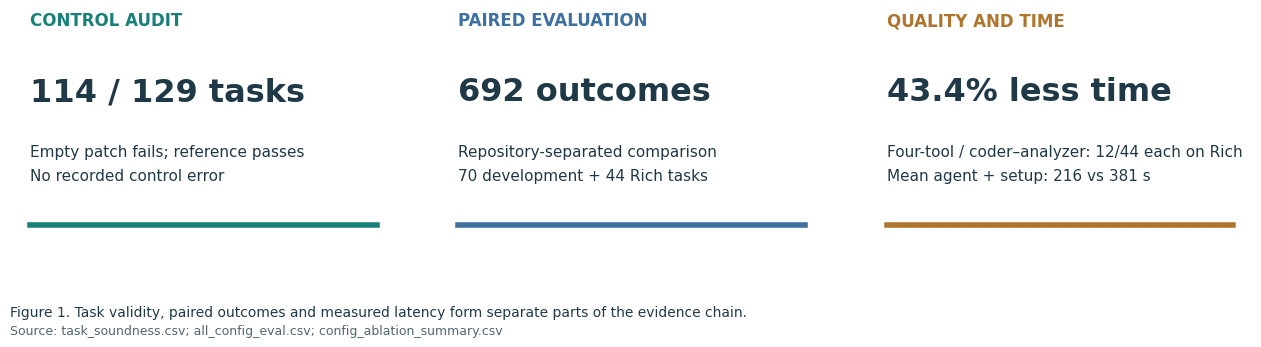

In [2]:
fig,axs=plt.subplots(1,3,figsize=(12.8,3.6))
rich=summary.query("split == 'held_out'").set_index('config')
saving=100*(1-rich.loc[SINGLE,'mean_seconds']/rich.loc[REFERENCE,'mean_seconds'])
cards=[('CONTROL AUDIT',f'{audit.sound.sum()} / {len(audit)} tasks','Empty patch fails; reference passes\nNo recorded control error',TEAL),('PAIRED EVALUATION',f'{len(outcomes)} outcomes','Repository-separated comparison\n70 development + 44 Rich tasks',BLUE),('QUALITY AND TIME',f'{saving:.1f}% less time','Four-tool / coder–analyzer: 12/44 each on Rich\nMean agent + setup: 216 vs 381 s',AMBER)]
for ax,(title,value,detail,color) in zip(axs,cards):
    ax.axis('off');ax.text(.02,.93,title,weight='bold',fontsize=12,color=color,transform=ax.transAxes)
    ax.text(.02,.61,value,fontsize=23,weight='bold',transform=ax.transAxes)
    ax.text(.02,.27,detail,fontsize=11,linespacing=1.7,transform=ax.transAxes)
    ax.plot([.02,.95],[.08,.08],color=color,lw=4,transform=ax.transAxes)
fig.subplots_adjust(left=.03,right=.99,top=.91,bottom=.26,wspace=.15)
save(fig,'01_graphical_abstract.png','Figure 1. Task validity, paired outcomes and measured latency form separate parts of the evidence chain.','task_soundness.csv; all_config_eval.csv; config_ablation_summary.csv')

*Figure 1. Graphical abstract. Counts concern public tasks; the time reduction is a local Rich comparison, not a hidden-hardware forecast.*

## 1. Introduction and setup

Issue-repair benchmarks require an agent to interpret a report, edit a repository and satisfy tests. This task formulation follows [SWE-bench](https://arxiv.org/abs/2310.06770). The [Gemma competition harness](https://www.kaggle.com/competitions/gemma-4-developer-agent/data) extracts a unified patch from the edited repository. The study uses the `gemma-4-31b-it-qat-w4a16-ct` model. Prompt, tool and budget configurations define the principal comparisons; the separate adaptation diagnostic appears in Appendix A.

The analysis joins [task soundness and local results](https://www.kaggle.com/datasets/dmitriigluzdov/gemma-4-task-soundness-and-local-results) with a [serving and adaptation verification kit](https://www.kaggle.com/datasets/dmitriigluzdov/gemma-4-serving-and-lora-verification-kit). Public task identifiers serve as join keys. Task text, patches, trajectories, training examples and model weights are excluded. The repository split assigns FastAPI, Requests and HTTPX to development and Rich to confirmation. This separation addresses repository overlap, while prior Rich exposure limits its role as an independent test.

## 2. Methods

### 2.1 Task soundness

Each public task receives an empty-patch control and an official reference-patch control. A task is retained when the empty patch fails, the reference patch passes and neither control records an error. Required skipped tests remain exclusions. Dependency-only overlays restore seven Rich environments and two FastAPI environments; tests, patches and grading logic remain unchanged. The mask is fixed before the reported agent comparisons and applies only to this recorded local environment.

### 2.2 Served-prompt fidelity

The recorded Agent Development Kit (ADK) request is compared with the serving parser and chat template. Ablations isolate retained reasoning fields and string-to-content-part conversion. Aggregate prompt-length agreement is distinguished from exact token identity. Historical parser behavior and the stronger live-token check are documented in Appendix A; the measurements do not certify a later serving stack.

### 2.3 Paired local evaluation

Eight configurations are evaluated on the same 70 sound development tasks. The coder–analyzer reference, four-tool single coder and development-selected six-minute budget schedule also receive 44-task Rich evaluation. The protocol fixes outgoing request seed 42 and uses one A100 with tensor parallelism 1 and eight concurrent evaluation workers. Every completed outcome remains in the denominator; recorded errors count unresolved. Agent-plus-setup wall time excludes patch grading.

The reference follows Roman Rozen's coder–analyzer architecture. The four-tool single coder changes the complete prompt, tool set and resource budget. The two-reviewer voting pipeline adds separate read-only source and contract reviews followed by reconciliation; its calls share the same model. The remaining configurations vary the reference's session cap, turn cap, schedule, localization instruction or analyzer requirement. Consequently, only appropriately matched parent comparisons isolate a single change. Configuration names and limits appear in Table 1.

Paired resolution differences use discordant task pairs. The two-sided exact sign test applies a binomial null with equal probability of either configuration winning a discordant pair. Its reported probabilities are exploratory: they do not adjust for repository clustering or multiple comparisons. The September measurements used a different request path and are excluded from this paired study.

### 2.4 Runtime model

Projected sequential runtime is

$$T_{\mathrm{hours}}=\frac{S+N\,\bar{t}\,f\,m}{3600},$$

where $S$ is startup time in seconds, $N$ is task count, $\bar{t}$ is mean task time in seconds, $f$ is an assumed hardware transfer factor and $m$ is a multiplicative planning margin. The principal scenario uses 120 tasks, 900 seconds of startup, $f=1$ and $m=1.25$. The [official evaluation allowance](https://www.kaggle.com/competitions/gemma-4-developer-agent/overview/evaluation) is 12 hours; the [organizer's queue clarification](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/747519) separates queue waiting from this allowance. Scenario parameters are assumptions, not measurements of private hardware. The organizer describes approximately 120 tasks across both score splits, processed sequentially within the allowance including model startup and sandbox setup; hidden grading is excluded. The fixed startup reserve is assumed, while measured task times already include per-task setup.

### 2.5 Reduced thinking budget

The primary archive changes only the Budget-Fit thinking ceiling from **4,096 to 2,048 tokens**, retaining thought summaries, temperature **0.2**, top-p **0.95**, an **8,192-token** output cap, an **eight-minute** session cap, **28** tool calls, **80** turns and a **240-second** command timeout. A [public sampling screen](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/746250) reports **50/129** solved at the smaller ceiling versus **48/129** at the reference ceiling. These are single-run observations under a **60-minute**, **50-call** screen, rather than measurements of this exact bundle. A lower ceiling may shorten task time when the ceiling binds; reduced latency and preserved repair quality remain hypotheses. No local quality or latency measurement exists for the exact variant. The attached sampling table and archive registry record the evidence and settings.

## 3. Results

### 3.1 Task audit and data quality

The audit records 119 reference-patch passes and two empty-patch passes. Accounting for control errors and skipped required tests leaves **114 sound tasks and 15 exclusions**. FastAPI contributes 62/67 sound tasks, Rich 44/48, Requests 7/13 and HTTPX 1/1. The resulting development and confirmation denominators are 70 and 44.

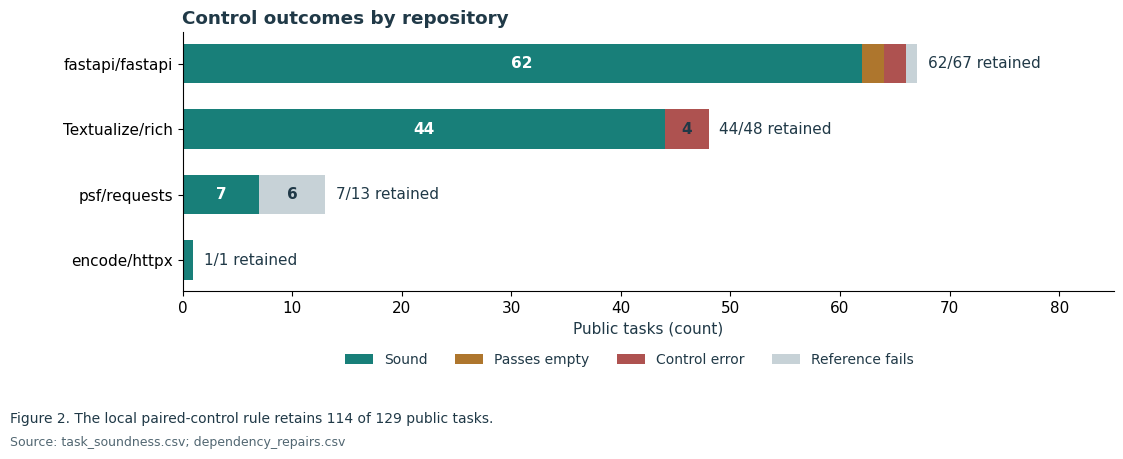

| Table | Rows | Duplicate keys | Missing cells |
| --- | --- | --- | --- |
| Control audit | 129 | 0 | 0 |
| Paired outcomes | 692 | 0 | 0 |

| Task join key | Empty resolves | Reference resolves | Empty exit code | Retained | Audit interpretation |
| --- | --- | --- | --- | --- | --- |
| fastapi_11194 | 0 | 1 | 1 | 1 | Sound |
| fastapi_14077 | 1 | 1 | 0 | 0 | Passes without a fix |
| rich_3480 | 0 | 1 | 124 | 0 | Empty control times out |

In [3]:
order=['fastapi/fastapi','Textualize/rich','psf/requests','encode/httpx']
statuses=['sound','passes_without_fix','control_error','gold_does_not_pass_local_grader']
counts=pd.crosstab(audit.repo,audit.status).reindex(index=order,columns=statuses,fill_value=0)
fig,ax=plt.subplots(figsize=(11.5,4.8));left=np.zeros(len(order))
for status,label,color in zip(statuses,['Sound','Passes empty','Control error','Reference fails'],[TEAL,AMBER,RED,GRAY]):
    values=counts[status].to_numpy();ax.barh(order,values,left=left,label=label,color=color,height=.6)
    for i,v in enumerate(values):
        if v>=3:ax.text(left[i]+v/2,i,str(v),ha='center',va='center',color='white' if status=='sound' else '#203947',weight='bold')
    left+=values
for i,repo in enumerate(order):ax.text(left[i]+1,i,f"{counts.loc[repo,'sound']}/{int(left[i])} retained",va='center')
ax.set_xlim(0,85);ax.invert_yaxis();ax.set_xlabel('Public tasks (count)');ax.set_title('Control outcomes by repository')
ax.legend(ncol=4,loc='upper center',bbox_to_anchor=(.48,-.19),frameon=False,fontsize=10)
fig.subplots_adjust(left=.17,right=.98,top=.87,bottom=.33)
save(fig,'02_task_soundness.png','Figure 2. The local paired-control rule retains 114 of 129 public tasks.','task_soundness.csv; dependency_repairs.csv')
quality=pd.DataFrame([{'Table':'Control audit','Rows':len(audit),'Duplicate keys':int(audit.task_id.duplicated().sum()),'Missing cells':int(audit.isna().sum().sum())},{'Table':'Paired outcomes','Rows':len(outcomes),'Duplicate keys':int(outcomes.duplicated(['config','split','task_id']).sum()),'Missing cells':int(outcomes.isna().sum().sum())}])
table(quality)
examples=audit.set_index('task_id').loc[['fastapi_11194','fastapi_14077','rich_3480'],['empty_resolved','gold_resolved','empty_exit_code','sound']].reset_index()
examples['Audit interpretation']=['Sound','Passes without a fix','Empty control times out']
examples.columns=['Task join key','Empty resolves','Reference resolves','Empty exit code','Retained','Audit interpretation'];table(examples)

*Figure 2. Exclusions remain visible by repository. The adjacent tables report missingness, duplicate keys and representative control outcomes. Exit code 124 identifies the timed-out empty control in the excluded Rich example. The frozen audit combines control results with reviewed exclusions; raw error flags alone do not reconstruct the mask. Binary resolution is the study outcome.*

### 3.2 Paired quality and latency

**Table 1.** Completed configuration comparisons. Rich entries marked “Not measured” have no confirmation outcome. Development times include setup and exclude grading; the 95th percentile (p95) describes task latency, not a confidence bound on total runtime. Source: `config_ablation_summary.csv` and `all_config_eval.csv`.

| Configuration | Development | Rich | Mean / p95 (s) | Session (min) / calls |
| --- | --- | --- | --- | --- |
| Rozen coder–analyzer reference | 16/70 | 12/44 | 341 / 975 | 60 / 100 |
| Four-tool single coder | 27/70 | 12/44 | 219 / 305 | 5 / 20 |
| Six-minute reference | 15/70 | Not measured | 240 / 364 | 6 / 100 |
| Six-minute reference with 150 turns | 16/70 | Not measured | 248 / 364 | 6 / 100 |
| Two-reviewer voting pipeline | 13/70 | Not measured | 259 / 364 | 6 / 100 |
| Six-minute budget schedule | 18/70 | 7/44 | 230 / 364 | 6 / 100 |
| Source-first localization | 15/70 | Not measured | 256 / 364 | 6 / 100 |
| Optional analyzer | 18/70 | Not measured | 275 / 364 | 6 / 100 |

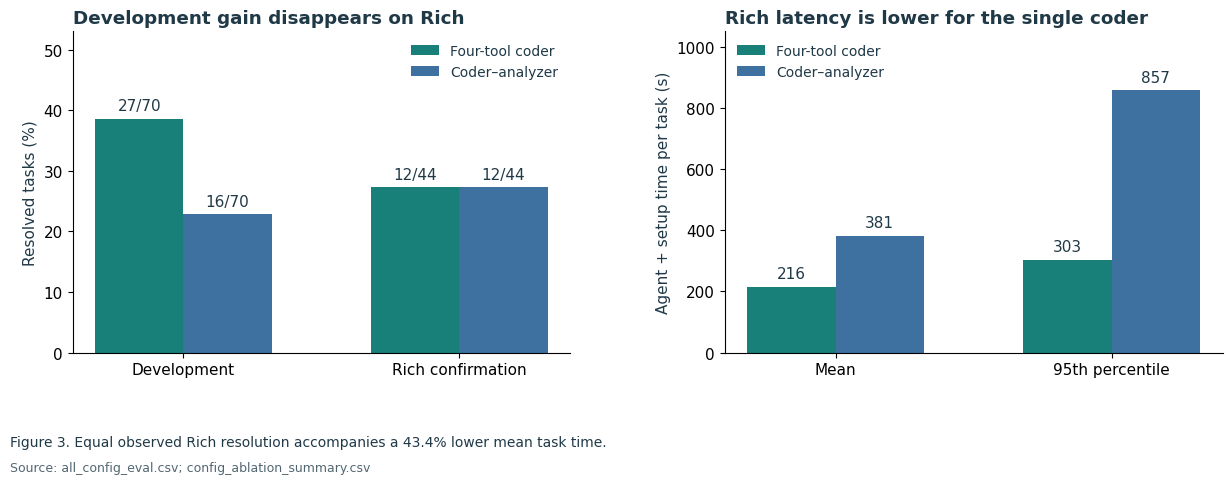

In [4]:
order=[REFERENCE,SINGLE,'Six-minute reference','Six-minute reference with 150 turns','Two-reviewer voting pipeline',SCHEDULE,'Source-first localization','Optional analyzer']
rows=[]
for config in order:
    d=summary.query("config == @config and split == 'development'").iloc[0]
    r=summary.query("config == @config and split == 'held_out'")
    rows.append({'Configuration':config,'Development':f'{d.resolved}/{d.n}','Rich':f'{r.iloc[0].resolved}/{r.iloc[0].n}' if len(r) else 'Not measured','Mean / p95 (s)':f'{d.mean_seconds:.0f} / {d.p95_seconds:.0f}','Session (min) / calls':f'{d.max_time_minutes} / {d.max_tool_calls}'})
table(pd.DataFrame(rows))
fig,(ax,bx)=plt.subplots(1,2,figsize=(12.5,5.1));x=np.arange(2);w=.32
for config,offset,color,label in [(SINGLE,-w/2,TEAL,'Four-tool coder'),(REFERENCE,w/2,BLUE,'Coder–analyzer')]:
    sub=summary[summary.config==config].set_index('split');c=sub.loc[['development','held_out'],'resolved'].to_numpy();n=sub.loc[['development','held_out'],'n'].to_numpy()
    bars=ax.bar(x+offset,100*c/n,w,color=color,label=label);ax.bar_label(bars,labels=[f'{int(a)}/{int(b)}' for a,b in zip(c,n)],padding=4)
    r=sub.loc['held_out'];bars=bx.bar(x+offset,[r.mean_seconds,r.p95_seconds],w,color=color,label=label);bx.bar_label(bars,labels=[f'{r.mean_seconds:.0f}',f'{r.p95_seconds:.0f}'],padding=4)
ax.set_xticks(x,['Development','Rich confirmation']);ax.set_ylim(0,53);ax.set_ylabel('Resolved tasks (%)');ax.set_title('Development gain disappears on Rich');ax.legend(frameon=False,fontsize=10)
bx.set_xticks(x,['Mean','95th percentile']);bx.set_ylim(0,1050);bx.set_ylabel('Agent + setup time per task (s)');bx.set_title('Rich latency is lower for the single coder');bx.legend(frameon=False,fontsize=10)
fig.subplots_adjust(left=.07,right=.99,top=.87,bottom=.24,wspace=.31)
save(fig,'03_paired_quality_time.png','Figure 3. Equal observed Rich resolution accompanies a 43.4% lower mean task time.','all_config_eval.csv; config_ablation_summary.csv')

*Figure 3. The four-tool coder resolves 27/70 development tasks versus 16/70 for the reference, with 14 wins and three losses (exact sign p = 0.0127). Rich resolution is 12/44 each, with five wins and five losses (p = 1.0). Rich mean/p95 times are 215.65/303.01 seconds for the single coder and 381.22/856.96 seconds for the reference. Equal observed resolution does not establish equivalence of underlying quality.*

The development-selected six-minute budget schedule resolves **7/44 Rich tasks** versus the reference's **12/44**, with one win and six losses (p = 0.125). The two-reviewer voting pipeline resolves **13/70 development tasks** versus **16/70**, with three wins and six losses. These observations provide no basis for promoting either design over the reference. The paired statistics are available in `paired_comparisons.csv`.

Coverage varies with the evaluated configuration set. Development contains 37 tasks solved by none, 28 by some and five by all eight configurations. Rich contains 27 solved by none, 12 by some and five by all three. These are descriptive coverage labels, not intrinsic task difficulty. Recorded outcome categories preserve errors and empty patches without inferring behavioral root causes.

### 3.3 Runtime sensitivity

With 120 sequential tasks and 900 seconds of startup, the 12-hour allowance permits **352.5 seconds per task** at no margin, or **282 seconds** with a 25% task-time margin. An eight-minute cap reached on every task consumes **16 hours before startup**. An additional minute per task adds two hours. A high session cap is therefore feasible only when enough tasks terminate earlier.

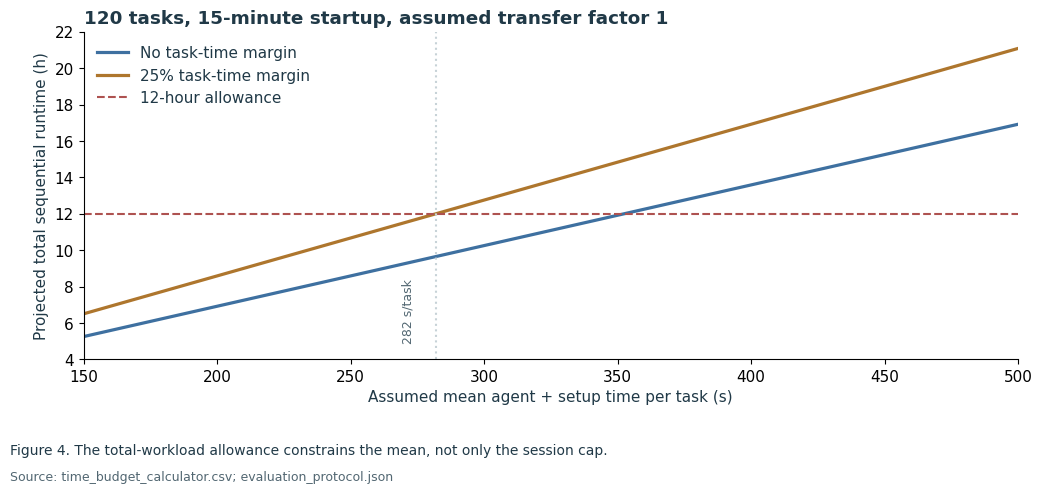

| Configuration | Mean / p95 (s) | Mean-based total (h) | Headroom to limit (h) | All tasks at p95 (h) |
| --- | --- | --- | --- | --- |
| Four-tool single coder | 215.65 / 303.01 | 7.44 | 4.56 | 10.35 |
| Rozen coder–analyzer reference | 381.22 / 856.96 | 12.96 | -0.96 | 28.82 |
| Six-minute budget schedule | 235.20 / 362.91 | 8.09 | 3.91 | 12.35 |
| Budget-Fit single agent | Not measured | Not measured | Not measured | Not measured |
| Issue-contract prompt variant | Not measured | Not measured | Not measured | Not measured |
| Reduced-thinking budget-fit | Not measured | Not measured | Not measured | Not measured |

In [5]:
assumptions=protocol['runtime_assumptions'];N=assumptions['task_count'];S=assumptions['startup_seconds']
limit=assumptions['limit_hours'];margin=assumptions['safety_factor'];allowed=(limit*3600-S)/(N*margin)
assert abs(allowed-282)<1e-9
fig,ax=plt.subplots(figsize=(10.5,5.2));seconds=np.linspace(150,500,101)
for m,color,label in [(1,BLUE,'No task-time margin'),(margin,AMBER,'25% task-time margin')]:ax.plot(seconds,(S+N*seconds*m)/3600,color=color,lw=2.3,label=label)
ax.axhline(limit,color=RED,ls='--',label='12-hour allowance');ax.axvline(allowed,color=GRAY,ls=':')
ax.text(allowed-8,4.9,'282 s/task',rotation=90,ha='right',va='bottom',fontsize=9,color='#526772')
ax.set_xlim(150,500);ax.set_ylim(4,22);ax.set_xlabel('Assumed mean agent + setup time per task (s)');ax.set_ylabel('Projected total sequential runtime (h)')
ax.set_title('120 tasks, 15-minute startup, assumed transfer factor 1');ax.legend(frameon=False,loc='upper left')
fig.subplots_adjust(left=.09,right=.98,top=.87,bottom=.24)
save(fig,'04_runtime_sensitivity.png','Figure 4. The total-workload allowance constrains the mean, not only the session cap.','time_budget_calculator.csv; evaluation_protocol.json')
rt=budget_summary.copy()
def measured(x):return 'Not measured' if pd.isna(x) else f'{x:.2f}'
rt['Mean / p95 (s)']=[f'{a:.2f} / {b:.2f}' if pd.notna(a) else 'Not measured' for a,b in zip(rt.mean_seconds,rt.p95_seconds)]
for field in ['total_hours_mean','headroom_hours_mean','total_hours_at_p95']:rt[field]=rt[field].map(measured)
rt=rt[['configuration','Mean / p95 (s)','total_hours_mean','headroom_hours_mean','total_hours_at_p95']]
rt.columns=['Configuration','Mean / p95 (s)','Mean-based total (h)','Headroom to limit (h)','All tasks at p95 (h)'];table(rt)

*Figure 4. Explicit runtime scenarios. The adjacent runtime table uses approximately 120 tasks plus a 900-second startup reserve, no task-time margin and transfer factor one. The all-tasks-at-p95 column is a stress scenario, not the p95 of the total workload. Negative headroom exceeds the 12-hour allowance. Eight-worker A100 task latencies do not measure sequential private-hardware throughput. Unmeasured latency remains explicit for the three packaged configurations. Source: runtime_budget_summary.csv.*

### 3.4 Dated public observations

The completed public observations include **0.18** for the unchanged budget-fit reference, **0.17** for the issue-contract prompt variant and **0.13** for the alternative budget-fit prompt. The identical coder–analyzer archive scores **0.10** and **0.06** on separate dates; its author-reported score is **0.12**. The four-tool coder records **0.06** under the earlier scorer and **0.10** under the later scorer, with different archive identities. The two-reviewer voting pipeline records **0.08**. These dated observations do not isolate prompt, scoring or stochastic effects. The table dates are submission dates for reproduced observations and the report date for the author observation. All listed completed statuses were checked on October 13, 2026; submission timestamps do not measure completion time. Incomplete attempts are omitted.

In [6]:
observations=lb[['record_date','configuration','public_score','observation_type','archive_sha256']].copy()
observations.public_score=observations.public_score.map(lambda x:f'{float(x):.2f}')
observations.archive_sha256=observations.archive_sha256.map(lambda x:'Not established' if x=='not_established' else x[:12]+'…')
observations.columns=['Submission / report date (UTC)','Configuration','Public score','Evidence type','Archive SHA-256 prefix'];table(observations)
selected=['Budget-Fit single agent','Calibrated single coder','Contract-first agent','Budget-aware coder','SuperAgent','Direct-code verifier','Coder–analyzer baseline']
public=catalogue[catalogue.configuration.isin(selected)][['configuration','author','best_public_score','license','score_source']].copy()
public.best_public_score=public.best_public_score.map(lambda v:'Not verified' if pd.isna(v) else f'{v:.2f}')
public.score_source=public.score_source.map(lambda u:f'[Source]({u})')
public.columns=['Public notebook','Author','Best public score','License','Evidence'];table(public)

| Submission / report date (UTC) | Configuration | Public score | Evidence type | Archive SHA-256 prefix |
| --- | --- | --- | --- | --- |
| 2026-09-23 | Rozen coder–analyzer reference | 0.12 | Author-reported public score | f3534769cd8c… |
| 2026-09-26 | Four-tool single coder (earlier scorer) | 0.06 | Reproduced public score | a9595595feee… |
| 2026-09-30 | Eight-minute coder–analyzer | 0.08 | Reproduced public score | 2ff5e0145a9a… |
| 2026-10-03 | Rozen coder–analyzer reference | 0.10 | Reproduced public score | f3534769cd8c… |
| 2026-10-05 | Two-reviewer voting pipeline | 0.08 | Reproduced public score | fc57daa81a8b… |
| 2026-10-06 | Rozen coder–analyzer reference | 0.06 | Reproduced public score | f3534769cd8c… |
| 2026-10-07 | Four-tool single coder (current scorer) | 0.10 | Reproduced public score | 909d5cb7c958… |
| 2026-10-08 | Budget-Fit single agent | 0.18 | Reproduced public score | eb3d5ebf21ce… |
| 2026-10-10 | Alternative budget-fit prompt | 0.13 | Reproduced public score | 8dfd2bf8ddfb… |
| 2026-10-11 | Issue-contract prompt variant | 0.17 | Reproduced public score | 1ad3e3d5537b… |

| Public notebook | Author | Best public score | License | Evidence |
| --- | --- | --- | --- | --- |
| Budget-Fit single agent | verracodeguacas | 0.18 | Apache-2.0 | [Source](https://www.kaggle.com/code/verracodeguacas/gemma-4-agent-budget-fit-single-agent?scriptVersionId=355310852) |
| Budget-aware coder | flexonafft | 0.18 | Apache-2.0 | [Source](https://www.kaggle.com/code/flexonafft/gemma-4-budget-aware-coding-agent-v2?scriptVersionId=356722956) |
| Calibrated single coder | lavinwins | 0.18 | Apache-2.0 | [Source](https://www.kaggle.com/code/lavinwins/gemma-4-autonomous-developer-agent-calibrated-sin?scriptVersionId=355611106) |
| Contract-first agent | nilanjansaha123 | 0.18 | Apache-2.0 | [Source](https://www.kaggle.com/code/nilanjansaha123/gemma-4-dev-agent-contract-first-1-agent-bundle?scriptVersionId=357147785) |
| Direct-code verifier | nihilisticneuralnet | 0.17 | Apache-2.0 | [Source](https://www.kaggle.com/code/nihilisticneuralnet/gemma-4-developer-agent-direct-code-verifier?scriptVersionId=356566368) |
| SuperAgent | matterhorn3838 | 0.17 | Apache-2.0 | [Source](https://www.kaggle.com/code/matterhorn3838/gemma-4-superagent?scriptVersionId=355922587) |
| Coder–analyzer baseline | romanrozen | 0.12 | Apache-2.0 | [Source](https://www.kaggle.com/code/romanrozen/gemma-eda-baseline-for-a-start-lb-top-1?scriptVersionId=352216783) |

Full archive hashes and source links appear in the attached leaderboard observations. The selected public references above and the full attached catalogue record score badges and licence notices checked on October 13, 2026. Best-score links identify the scored source; the latest source may differ. Missing badges remain unverified, irrespective of scores advertised in notebook titles. Catalogue entries and credited bundles are text and source links, not additional notebook attachments. Scores obtained on different dates can reflect stochastic generation, infrastructure and scorer changes; the available observations do not separate those effects.

## 4. Discussion

The four-tool coder's development advantage fails to transfer to Rich, whereas its lower measured latency persists. This distinction favors evaluating quality and time jointly. It does not establish that the four-tool design or the separately scored Budget-Fit configuration will perform better on private repositories. The negative budget-schedule confirmation likewise shows why development selection requires subsequent evaluation on independent repositories.

Additional reviewer calls consume time and may share model errors. Reviewer agreement can reflect common errors rather than independent evidence. Future comparisons should freeze the parent bundle and budget, then measure net resolutions, regressions and total runtime. A matched test of the reduced thinking ceiling can establish whether lower generation cost preserves repair quality within the same full-workload allowance.

The shipped reduced-thinking variant changes one generation setting. The unchanged budget-fit bundle and issue-contract prompt variant remain separate reference outputs. A lower ceiling reduces the permitted reasoning tokens per call; whether it reduces total task time depends on ceiling saturation and any compensating repair turns. The single public screen motivates this controlled comparison without establishing an advantage for the shipped archive.

## 5. Limitations

The soundness mask depends on the recorded local grader and dependency environment. Public tasks differ from private repositories; the study cannot estimate that shift from the available data. Development is dominated by FastAPI, and Rich supplies only one previously inspected confirmation repository. One request seed, within-repository dependence and multiple exploratory comparisons limit uncertainty claims. Complete-bundle changes confound individual prompt, tool and budget effects.

Measured A100 task latency under eight-worker load is not private-hardware throughput. Public-score differences across dates are observational. Historical serving checks apply to their recorded wheel hashes, not automatically to later scorer builds. The small adaptation mini-evaluation has limited power and repeated Rich exposure. No hidden-performance claim follows from the local audit, public leaderboard observations or archive compatibility checks.

## 6. Conclusion

Task controls, served-prompt fidelity and paired evaluation answer different validity questions. The present study finds a local latency reduction without a corresponding Rich resolution gain, a failed confirmation of a development-selected schedule, and a loss reduction that does not pass an adaptation quality gate. The next informative comparison is a frozen, paired test under the same overall resource limits, with independent confirmation. Additional verification, ensembling and external demonstrations require measured task-level benefit and a feasible full-workload runtime before adoption.

## References and attribution

1. Jimenez et al. [SWE-bench: Can Language Models Resolve Real-World GitHub Issues?](https://arxiv.org/abs/2310.06770). Issue-to-patch benchmark formulation.
2. Hu et al. [LoRA: Low-Rank Adaptation of Large Language Models](https://arxiv.org/abs/2106.09685). Low-rank weight updates.
3. Google/Kaggle. [Competition data and harness](https://www.kaggle.com/competitions/gemma-4-developer-agent/data), [evaluation](https://www.kaggle.com/competitions/gemma-4-developer-agent/overview/evaluation) and [official starter](https://www.kaggle.com/code/ryanholbrook/getting-started-gemma-4-developer-agent).
4. **verracodeguacas**, [Budget-Fit Single Agent](https://www.kaggle.com/code/verracodeguacas/gemma-4-agent-budget-fit-single-agent), Apache 2.0. Source of the unchanged reference archive and configuration.
5. **matterhorn3838**, [SuperAgent](https://www.kaggle.com/code/matterhorn3838/gemma-4-superagent), Apache 2.0. Source of the issue-contract and sibling-pattern workflow informing the prompt variant.
6. **lavinwins**, [Calibrated Single](https://www.kaggle.com/code/lavinwins/gemma-4-autonomous-developer-agent-calibrated-sin), Apache 2.0. Credited comparative design; no isolated causal contribution is measured here.
7. **Roman Rozen**, [coder–analyzer baseline](https://www.kaggle.com/code/romanrozen/gemma-eda-baseline-for-a-start-lb-top-1), Apache 2.0. Reference architecture and attributed public-score observation.
8. KE WU and competition organizers. [Served reasoning-field discussion](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/744354). Historical parser discrepancy and subsequent correction notice.

Original measurements and documentation are released under **CC BY 4.0**. Reference utilities and all generated agent bundles use **Apache License 2.0**. Upstream credits and derivative notices are preserved. The unchanged reference and issue-contract archive retain their original embedded notices and byte identities; the reduced-thinking archive changes only its declared thinking ceiling.

## Appendix A. Serving fidelity and low-rank adaptation

### A.1 Historical prompt and inference-effect checks

The inspected ADK replay places previous thoughts in `reasoning_content`, whereas the recorded vLLM parser reads `reasoning`. String content is also wrapped as text parts before templating. Applying both transformations matches **803/803 native prompt lengths** and **133/133 Rich prompt lengths**; the original renderer matches **0/803**. A separate live check establishes token identity for **5/5 development requests**. Joint prompt-and-completion length agreement is **765/803**, illustrating that prompt-length matching alone is insufficient. These results concern the historical package builds identified by hashes in the verification kit. The organizer later reported a correction in the [reasoning-field discussion](https://www.kaggle.com/competitions/gemma-4-developer-agent/discussion/744354).

Low-rank adaptation (LoRA) adds $\Delta W=(\alpha/r)BA$ to a frozen projection. A zero-update example adapter is a loading control. A deliberately untrained rank-four, alpha-eight adapter across 410 projections tests whether serving produces a nonzero inference effect. At temperature zero and request seed 42, repeated-base and zero-update controls agree. Warmup drift is **0.125 nats**, giving a ten-times-drift threshold of **1.25 nats**. The diagnostic adapter excludes the base-leading token from the first-token top-20 set, implying a log-probability decrease of **at least 4.8921 nats**. This is a lower bound, not an exactly aligned delta or a repair-quality result.

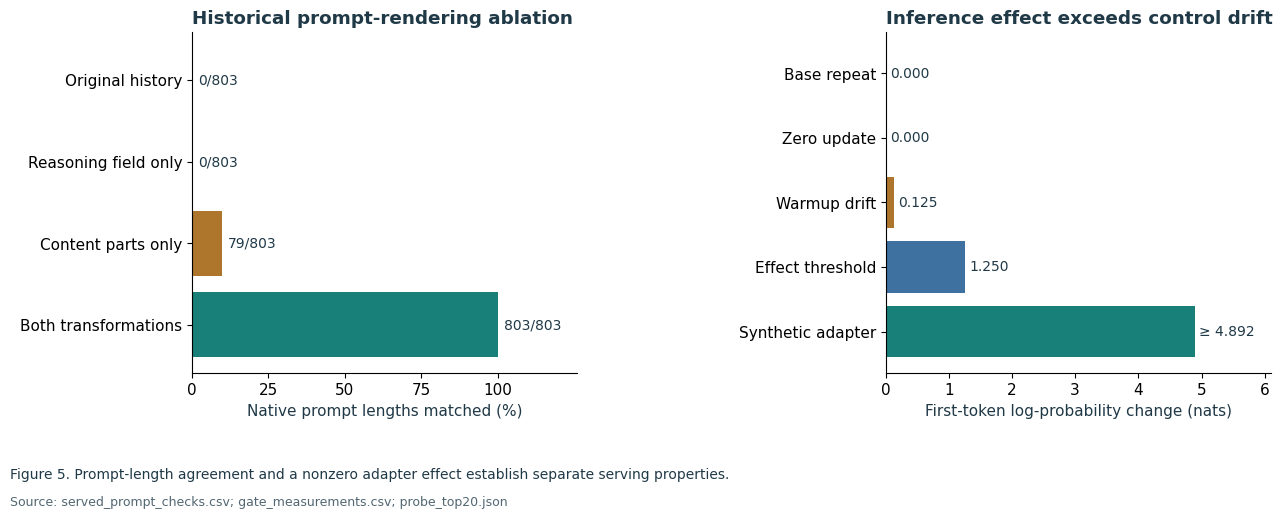

In [7]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(13,5.5))
r=render.query("cohort == 'native' and check == 'prompt_token_count'")
names={'old_history':'Original history','drop_reasoning_content_only':'Reasoning field only','content_parts_only':'Content parts only','served_history':'Both transformations'}
bars=ax.barh([names[x] for x in r.rendering],100*r.matched/r.total,color=[GRAY,GRAY,AMBER,TEAL]);ax.invert_yaxis()
for bar,row in zip(bars,r.itertuples()):ax.text(bar.get_width()+2,bar.get_y()+bar.get_height()/2,f'{row.matched}/{row.total}',va='center',fontsize=10)
ax.set_xlim(0,126);ax.set_xticks([0,25,50,75,100]);ax.set_xlabel('Native prompt lengths matched (%)');ax.set_title('Historical prompt-rendering ablation')
keys=['base_repeat_drift','zero_adapter_drift','warmup_drift','effect_threshold','strong_effect_lower_bound']
values=[gate[k] for k in keys];bars=bx.barh(['Base repeat','Zero update','Warmup drift','Effect threshold','Synthetic adapter'],values,color=[GRAY,GRAY,AMBER,BLUE,TEAL]);bx.invert_yaxis()
for i,(bar,v) in enumerate(zip(bars,values)):bx.text(v+.07,bar.get_y()+bar.get_height()/2,('≥ ' if i==4 else '')+f'{v:.3f}',va='center',fontsize=10)
bx.set_xlim(0,6.1);bx.set_xlabel('First-token log-probability change (nats)');bx.set_title('Inference effect exceeds control drift')
fig.subplots_adjust(left=.16,right=.99,top=.87,bottom=.25,wspace=.8)
save(fig,'05_serving_diagnostics.png','Figure 5. Prompt-length agreement and a nonzero adapter effect establish separate serving properties.','served_prompt_checks.csv; gate_measurements.csv; probe_top20.json')
scope={'__name__':'evidence_replay'};exec(compile(evidence(K,'probe_adapter_effect.py'),'probe_adapter_effect.py','exec'),scope)
replay=scope['assess'](json.loads(evidence(K,'probe_top20.json')))
assert replay['pass'] and replay['missing_token_drop_lower_bound']>replay['threshold']

*Figure 5. The left panel reports prompt-length equality, not full token identity. The right panel includes a conservative top-20-derived effect bound. The attached synthetic distributions reproduce the effect assessment on CPU. Historical package hashes and the compatible dependency lock are included in the verification kit.*

### A.2 Loss reduction and task outcomes

The short adaptation experiment uses rank 16, alpha 32, learning rate 0.0001 and seed 42. Training admits 412 turns from 23 development tasks, caps sequences at 8,192 tokens and runs 30 optimizer steps with gradient accumulation eight. Rich remains outside training. Only aggregate measurements are published.

Negative log-likelihood (NLL) is the token-mean negative natural logarithm of target probability. The final adapter reduces resolved-Rich action NLL by **40.7%** and thought NLL by **25.5%**. Overall NLL falls by **27.1%** on resolved Rich turns and **25.5%** on unresolved Rich turns. The similar reductions are compatible with broad distributional sharpening; they do not demonstrate better issue repair.

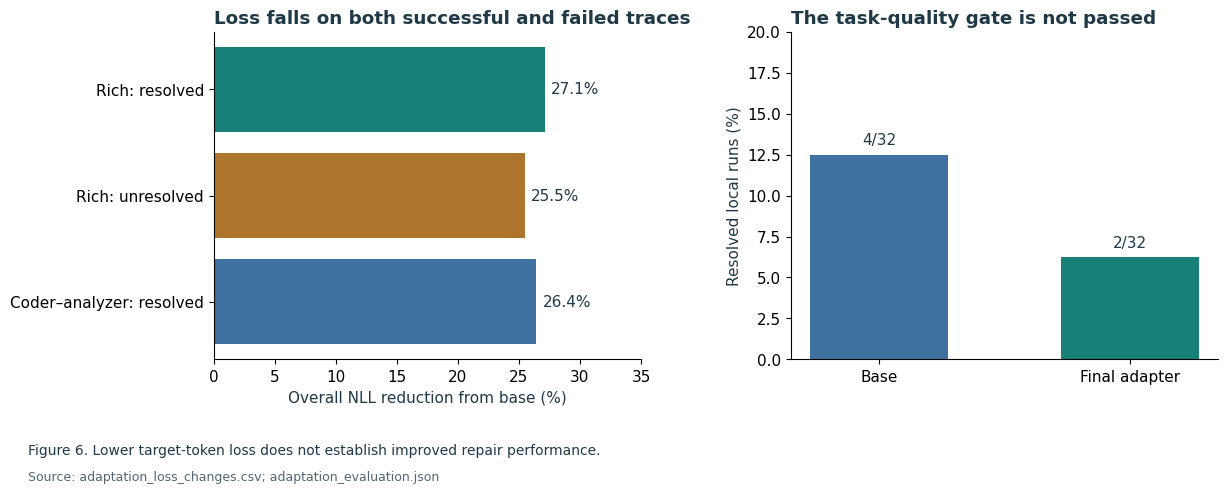

In [8]:
fig,(ax,bx)=plt.subplots(1,2,figsize=(12.4,5.2))
controls=loss.query("span == 'overall' and cohort != 'development_validation'").set_index('cohort')
cohorts=['rich_resolved','rich_unresolved','coder_analyzer_resolved'];v=[-controls.loc[x,'relative_change_pct'] for x in cohorts]
bars=ax.barh(['Rich: resolved','Rich: unresolved','Coder–analyzer: resolved'],v,color=[TEAL,AMBER,BLUE]);ax.invert_yaxis()
for b,value in zip(bars,v):ax.text(value+.5,b.get_y()+b.get_height()/2,f'{value:.1f}%',va='center')
ax.set_xlim(0,35);ax.set_xlabel('Overall NLL reduction from base (%)');ax.set_title('Loss falls on both successful and failed traces')
check=adaptation['criteria']['minieval_resolved_not_worse_than_base_minus_1'];n=check['runs'];values=[check['base'],check['adapter']]
bars=bx.bar(['Base','Final adapter'],100*np.array(values)/n,color=[BLUE,TEAL],width=.55);bx.bar_label(bars,labels=[f'{v}/{n}' for v in values],padding=5)
bx.set_ylim(0,20);bx.set_ylabel('Resolved local runs (%)');bx.set_title('The task-quality gate is not passed')
fig.subplots_adjust(left=.17,right=.98,top=.87,bottom=.24,wspace=.35)
save(fig,'06_adaptation_controls.png','Figure 6. Lower target-token loss does not establish improved repair performance.','adaptation_loss_changes.csv; adaptation_evaluation.json')

*Figure 6. The task comparison contains 16 Rich tasks at seeds 42 and 7, giving 32 runs per route, with two-minute caps. Base resolves 4/32 runs and the adapter 2/32. Final Rich NLL also rises from the intermediate checkpoint's 0.06779 to 0.07342 nats/token. These two failed criteria block promotion under the recorded gate; the experiment does not precisely estimate a small quality difference.*

The serving-effect check, rendering check and repair-quality check address distinct mechanisms. A loaded adapter can have no effective update; a lower token loss can coexist with worse task outcomes. Future adaptation comparisons require current-stack token checks, save/reload verification and independent repository-level evaluation.

## Appendix B. Deterministic agent archives

The notebook builds **`submission.zip`** containing the reduced-thinking budget-fit variant, **`budget_fit_reference.zip`** containing the unchanged budget-fit bundle, and **`issue_contract_prompt_variant.zip`** containing the issue-contract variant. The primary bundle differs from the budget-fit reference only in **thinking_budget: 4096 → 2048**; prompts, tools, thought retention and all other settings are unchanged. The public sampling observation is a single run under different session limits. No local quality or latency measurement exists for the exact shipped variant.

Sorted members, fixed timestamps and fixed permissions reproduce the registry SHA-256 hashes. Each archive has one root `agent.yaml`. The model-facing prompts and available upstream notices remain byte-identical to their references. All bundles use Apache License 2.0. CPU compilation with the current official compiler and harness packages passes; the attached receipt records wheel hashes and the resolved generation settings. Compilation and archive construction perform no model inference and establish no repair-quality result.

In [9]:
# Byte-preserved licensed bundle contents.
ISSUE_CONTRACT_FILES={'agent.yaml': 'name: swe_agent\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include prompts/system.md\ntools:\n  - run_command\n  - read_file\n  - edit_file\n  - write_file\n  - get_status\n  - submit_patch\n  - get_code_neighbors\n  - search_similar_code\n  - get_code_subgraph\ngenerate_content_config: !include configs/sampling.yaml\n', 'configs/sampling.yaml': 'temperature: 0.2\ntop_p: 0.95\nmax_output_tokens: 8192\nthinking_config:\n  thinking_budget: 4096\n  include_thoughts: true\n', 'eval_config.yaml': 'evaluation:\n  timeout_seconds: 240\n  max_tool_calls: 28\n  max_time_minutes: 8\n  max_turns: 80\n', 'prompts/system.md': 'You are an expert autonomous software engineer assigned to resolve an issue in a repository efficiently and decisively.\n\n## Core Objective: Fast, Minimal, and Precise Fixes\nAim to understand, resolve, and submit the fix in the minimum number of tool calls (under 8–10 turns). Move directly from the problem statement to the relevant files, apply the solution, verify with a targeted test, and submit.\n\n## Workflow\n\n### 1. Identify Target Files Immediately\n- Before the first tool call, extract the issue contract: required names, exception types/messages, return values, defaults and explicitly mentioned edge cases. Keep this checklist short and use it to choose the edit and targeted check; it requires no additional tool call.\n- Extract filenames, functions, classes, CLI subcommands, or error messages directly from the problem statement.\n- Read only the specific target files and lines using `read_file` or search tools. Do not wander across unrelated files.\n- If the problem statement does not provide explicit file paths, search for its most specific identifier or error string with `git grep -n "text" -- \'*.py\' | head -20`.\n- Do not use `search_similar_code`, `get_code_neighbors` or `get_code_subgraph`: they only accept exact fully-qualified ids and usually return nothing.\n\n### 2. Implement the Solution Directly\n- Apply the minimal necessary fix or feature directly to the source files using `edit_file` or `write_file`.\n- Strictly adhere to specified error strings, exception types, HTTP status codes, and API signatures.\n- For a new feature, follow the nearest existing sibling pattern, including required imports, exports or dispatch registration. Reuse the files already localized; keep the edit-by-call-12 deadline and existing verification budget.\n- For documentation code tasks (e.g. FastAPI), edit executable code under `docs_src/`.\n\n### 3. Run Targeted Tests Only (Existing Tests May Be Broken)\n- **Run ONLY Targeted Tests**: Run only the specific test file or test method directly verifying the bug or feature you modified (e.g. `pytest tests/test_target.py -k test_feature` or `python3 -m unittest tests.test_target`).\n- **Be Aware That Existing Tests May Be Broken**: Many repositories contain pre-existing test breakages, missing test data fixtures (e.g. `/test_data`), or environment import errors unrelated to your task.\n- **Do NOT Attempt to Fix Existing Tests**: If an existing test fails due to pre-existing repository issues or missing fixtures, IGNORE IT. Never spend turns attempting to repair pre-existing test failures, create test stubs, or alter test code.\n- **STRICT RULE: NEVER Run Bare Pytest or Full-Repo Sweeps**: NEVER run bare `pytest`, `pytest .`, `python3 -m unittest discover`, or full-repo test suites without specifying a target file. Full test suites take several minutes, cause catastrophic timeouts, and exhaust your turn and time budgets.\n- If you need to locate the test file, find it explicitly with `find tests -name "*<name>*.py"` instead of running the test runner across the repo.\n\n### 4. Immediate Patch Submission\n- Once your targeted test passes:\n  1. Call `submit_patch` immediately.\n  2. Verify `patch_size > 0` and `files_changed > 0`.\n  3. Output a short summary of the fix to end the session.\n\n## Budget: 28 tool calls, 8 minutes\n- You have at most 28 tool calls and 8 minutes for this task. When either runs out, the working tree is graded as it is, so an edit made in time counts even if you never reach `submit_patch`.\n- Use at most about 10 tool calls to find and read the code.\n- By your 12th tool call you must have edited a source file. If you have not, stop exploring and make your best-guess edit in the most likely place now. Runs that are still only reading after 12 calls almost never succeed; more reading does not help.\n- After your edit: one compile check or one targeted test, a correction if needed, then `submit_patch`. Do not start new exploration after your 20th tool call.\n\n## Anti-Patterns to Avoid\n- **NEVER modify, create, or delete test files** (`*_test.py`, `test_*.py`, or anything under `tests/`). All changes must be to source implementation files. Modifying tests results in an automatic evaluation failure.\n- **NEVER run full repository test suites** (e.g., bare `pytest` or `pytest .`) — always specify the exact test file path.\n- **NEVER attempt to fix or repair existing tests or pre-existing repository breakages** — your task is strictly to implement the fix for the reported issue in source code.\n- **NEVER search outside `/workspace`** for source files or packages (e.g., `/usr/local/lib/`, `/wheels/`, `/opt/`). All repository code and test dependencies are pre-installed. If `ModuleNotFoundError` occurs during test runs, focus on fixing code under `/workspace`, not looking for missing system packages.\n- Do NOT spend turns running broad exploratory searches if the file path or symbol is obvious.\n- Do NOT refactor or reformat unrelated functions or files.\n- Do NOT conclude without submitting a non-empty patch (`patch_size > 0`). Every task requires concrete source modifications. Concluding that the codebase is already clean without making changes is an anti-pattern.\n', 'ATTRIBUTION.md': "# D1 attribution and change notice — 2026-10-11\n\nDerived from Wilmer E. Henao (verracodeguacas), Budget-Fit Single Agent:\nhttps://www.kaggle.com/code/verracodeguacas/gemma-4-agent-budget-fit-single-agent\nApache-2.0. The four-file reference was reproduced by our notebook at public 0.18.\n\nTwo short prompt additions by Dmitrii Gluzdov: extract an issue contract without\nanother tool call, and follow sibling registration patterns within existing budgets.\nInspired by matterhorn3838's Apache-2.0 SuperAgent specification/sibling workflow:\nhttps://www.kaggle.com/code/matterhorn3838/gemma-4-superagent\nAll agent YAML, generation settings and evaluation budgets are unchanged.\nD1 has no local quality measurement and no public score. It is ranked below the\nunchanged Budget-Fit reference; compiler success is only compatibility evidence.\n", 'LICENSE.txt': '\n                                 Apache License\n                           Version 2.0, January 2004\n                        http://www.apache.org/licenses/\n\n   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION\n\n   1. Definitions.\n\n      "License" shall mean the terms and conditions for use, reproduction,\n      and distribution as defined by Sections 1 through 9 of this document.\n\n      "Licensor" shall mean the copyright owner or entity authorized by\n      the copyright owner that is granting the License.\n\n      "Legal Entity" shall mean the union of the acting entity and all\n      other entities that control, are controlled by, or are under common\n      control with that entity. For the purposes of this definition,\n      "control" means (i) the power, direct or indirect, to cause the\n      direction or management of such entity, whether by contract or\n      otherwise, or (ii) ownership of fifty percent (50%) or more of the\n      outstanding shares, or (iii) beneficial ownership of such entity.\n\n      "You" (or "Your") shall mean an individual or Legal Entity\n      exercising permissions granted by this License.\n\n      "Source" form shall mean the preferred form for making modifications,\n      including but not limited to software source code, documentation\n      source, and configuration files.\n\n      "Object" form shall mean any form resulting from mechanical\n      transformation or translation of a Source form, including but\n      not limited to compiled object code, generated documentation,\n      and conversions to other media types.\n\n      "Work" shall mean the work of authorship, whether in Source or\n      Object form, made available under the License, as indicated by a\n      copyright notice that is included in or attached to the work\n      (an example is provided in the Appendix below).\n\n      "Derivative Works" shall mean any work, whether in Source or Object\n      form, that is based on (or derived from) the Work and for which the\n      editorial revisions, annotations, elaborations, or other modifications\n      represent, as a whole, an original work of authorship. For the purposes\n      of this License, Derivative Works shall not include works that remain\n      separable from, or merely link (or bind by name) to the interfaces of,\n      the Work and Derivative Works thereof.\n\n      "Contribution" shall mean any work of authorship, including\n      the original version of the Work and any modifications or additions\n      to that Work or Derivative Works thereof, that is intentionally\n      submitted to Licensor for inclusion in the Work by the copyright owner\n      or by an individual or Legal Entity authorized to submit on behalf of\n      the copyright owner. For the purposes of this definition, "submitted"\n      means any form of electronic, verbal, or written communication sent\n      to the Licensor or its representatives, including but not limited to\n      communication on electronic mailing lists, source code control systems,\n      and issue tracking systems that are managed by, or on behalf of, the\n      Licensor for the purpose of discussing and improving the Work, but\n      excluding communication that is conspicuously marked or otherwise\n      designated in writing by the copyright owner as "Not a Contribution."\n\n      "Contributor" shall mean Licensor and any individual or Legal Entity\n      on behalf of whom a Contribution has been received by Licensor and\n      subsequently incorporated within the Work.\n\n   2. Grant of Copyright License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      copyright license to reproduce, prepare Derivative Works of,\n      publicly display, publicly perform, sublicense, and distribute the\n      Work and such Derivative Works in Source or Object form.\n\n   3. Grant of Patent License. Subject to the terms and conditions of\n      this License, each Contributor hereby grants to You a perpetual,\n      worldwide, non-exclusive, no-charge, royalty-free, irrevocable\n      (except as stated in this section) patent license to make, have made,\n      use, offer to sell, sell, import, and otherwise transfer the Work,\n      where such license applies only to those patent claims licensable\n      by such Contributor that are necessarily infringed by their\n      Contribution(s) alone or by combination of their Contribution(s)\n      with the Work to which such Contribution(s) was submitted. If You\n      institute patent litigation against any entity (including a\n      cross-claim or counterclaim in a lawsuit) alleging that the Work\n      or a Contribution incorporated within the Work constitutes direct\n      or contributory patent infringement, then any patent licenses\n      granted to You under this License for that Work shall terminate\n      as of the date such litigation is filed.\n\n   4. Redistribution. You may reproduce and distribute copies of the\n      Work or Derivative Works thereof in any medium, with or without\n      modifications, and in Source or Object form, provided that You\n      meet the following conditions:\n\n      (a) You must give any other recipients of the Work or\n          Derivative Works a copy of this License; and\n\n      (b) You must cause any modified files to carry prominent notices\n          stating that You changed the files; and\n\n      (c) You must retain, in the Source form of any Derivative Works\n          that You distribute, all copyright, patent, trademark, and\n          attribution notices from the Source form of the Work,\n          excluding those notices that do not pertain to any part of\n          the Derivative Works; and\n\n      (d) If the Work includes a "NOTICE" text file as part of its\n          distribution, then any Derivative Works that You distribute must\n          include a readable copy of the attribution notices contained\n          within such NOTICE file, excluding those notices that do not\n          pertain to any part of the Derivative Works, in at least one\n          of the following places: within a NOTICE text file distributed\n          as part of the Derivative Works; within the Source form or\n          documentation, if provided along with the Derivative Works; or,\n          within a display generated by the Derivative Works, if and\n          wherever such third-party notices normally appear. The contents\n          of the NOTICE file are for informational purposes only and\n          do not modify the License. You may add Your own attribution\n          notices within Derivative Works that You distribute, alongside\n          or as an addendum to the NOTICE text from the Work, provided\n          that such additional attribution notices cannot be construed\n          as modifying the License.\n\n      You may add Your own copyright statement to Your modifications and\n      may provide additional or different license terms and conditions\n      for use, reproduction, or distribution of Your modifications, or\n      for any such Derivative Works as a whole, provided Your use,\n      reproduction, and distribution of the Work otherwise complies with\n      the conditions stated in this License.\n\n   5. Submission of Contributions. Unless You explicitly state otherwise,\n      any Contribution intentionally submitted for inclusion in the Work\n      by You to the Licensor shall be under the terms and conditions of\n      this License, without any additional terms or conditions.\n      Notwithstanding the above, nothing herein shall supersede or modify\n      the terms of any separate license agreement you may have executed\n      with Licensor regarding such Contributions.\n\n   6. Trademarks. This License does not grant permission to use the trade\n      names, trademarks, service marks, or product names of the Licensor,\n      except as required for reasonable and customary use in describing the\n      origin of the Work and reproducing the content of the NOTICE file.\n\n   7. Disclaimer of Warranty. Unless required by applicable law or\n      agreed to in writing, Licensor provides the Work (and each\n      Contributor provides its Contributions) on an "AS IS" BASIS,\n      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or\n      implied, including, without limitation, any warranties or conditions\n      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A\n      PARTICULAR PURPOSE. You are solely responsible for determining the\n      appropriateness of using or redistributing the Work and assume any\n      risks associated with Your exercise of permissions under this License.\n\n   8. Limitation of Liability. In no event and under no legal theory,\n      whether in tort (including negligence), contract, or otherwise,\n      unless required by applicable law (such as deliberate and grossly\n      negligent acts) or agreed to in writing, shall any Contributor be\n      liable to You for damages, including any direct, indirect, special,\n      incidental, or consequential damages of any character arising as a\n      result of this License or out of the use or inability to use the\n      Work (including but not limited to damages for loss of goodwill,\n      work stoppage, computer failure or malfunction, or any and all\n      other commercial damages or losses), even if such Contributor\n      has been advised of the possibility of such damages.\n\n   9. Accepting Warranty or Additional Liability. While redistributing\n      the Work or Derivative Works thereof, You may choose to offer,\n      and charge a fee for, acceptance of support, warranty, indemnity,\n      or other liability obligations and/or rights consistent with this\n      License. However, in accepting such obligations, You may act only\n      on Your own behalf and on Your sole responsibility, not on behalf\n      of any other Contributor, and only if You agree to indemnify,\n      defend, and hold each Contributor harmless for any liability\n      incurred by, or claims asserted against, such Contributor by reason\n      of your accepting any such warranty or additional liability.\n\n   END OF TERMS AND CONDITIONS\n\n   APPENDIX: How to apply the Apache License to your work.\n\n      To apply the Apache License to your work, attach the following\n      boilerplate notice, with the fields enclosed by brackets "[]"\n      replaced with your own identifying information. (Don\'t include\n      the brackets!)  The text should be enclosed in the appropriate\n      comment syntax for the file format. We also recommend that a\n      file or class name and description of purpose be included on the\n      same "printed page" as the copyright notice for easier\n      identification within third-party archives.\n\n   Copyright [yyyy] [name of copyright owner]\n\n   Licensed under the Apache License, Version 2.0 (the "License");\n   you may not use this file except in compliance with the License.\n   You may obtain a copy of the License at\n\n       http://www.apache.org/licenses/LICENSE-2.0\n\n   Unless required by applicable law or agreed to in writing, software\n   distributed under the License is distributed on an "AS IS" BASIS,\n   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.\n   See the License for the specific language governing permissions and\n   limitations under the License.'}
REFERENCE_FILES={'agent.yaml': 'name: swe_agent\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include prompts/system.md\ntools:\n  - run_command\n  - read_file\n  - edit_file\n  - write_file\n  - get_status\n  - submit_patch\n  - get_code_neighbors\n  - search_similar_code\n  - get_code_subgraph\ngenerate_content_config: !include configs/sampling.yaml\n', 'configs/sampling.yaml': 'temperature: 0.2\ntop_p: 0.95\nmax_output_tokens: 8192\nthinking_config:\n  thinking_budget: 4096\n  include_thoughts: true\n', 'eval_config.yaml': 'evaluation:\n  timeout_seconds: 240\n  max_tool_calls: 28\n  max_time_minutes: 8\n  max_turns: 80\n', 'prompts/system.md': 'You are an expert autonomous software engineer assigned to resolve an issue in a repository efficiently and decisively.\n\n## Core Objective: Fast, Minimal, and Precise Fixes\nAim to understand, resolve, and submit the fix in the minimum number of tool calls (under 8–10 turns). Move directly from the problem statement to the relevant files, apply the solution, verify with a targeted test, and submit.\n\n## Workflow\n\n### 1. Identify Target Files Immediately\n- Extract filenames, functions, classes, CLI subcommands, or error messages directly from the problem statement.\n- Read only the specific target files and lines using `read_file` or search tools. Do not wander across unrelated files.\n- If the problem statement does not provide explicit file paths, search for its most specific identifier or error string with `git grep -n "text" -- \'*.py\' | head -20`.\n- Do not use `search_similar_code`, `get_code_neighbors` or `get_code_subgraph`: they only accept exact fully-qualified ids and usually return nothing.\n\n### 2. Implement the Solution Directly\n- Apply the minimal necessary fix or feature directly to the source files using `edit_file` or `write_file`.\n- Strictly adhere to specified error strings, exception types, HTTP status codes, and API signatures.\n- For documentation code tasks (e.g. FastAPI), edit executable code under `docs_src/`.\n\n### 3. Run Targeted Tests Only (Existing Tests May Be Broken)\n- **Run ONLY Targeted Tests**: Run only the specific test file or test method directly verifying the bug or feature you modified (e.g. `pytest tests/test_target.py -k test_feature` or `python3 -m unittest tests.test_target`).\n- **Be Aware That Existing Tests May Be Broken**: Many repositories contain pre-existing test breakages, missing test data fixtures (e.g. `/test_data`), or environment import errors unrelated to your task.\n- **Do NOT Attempt to Fix Existing Tests**: If an existing test fails due to pre-existing repository issues or missing fixtures, IGNORE IT. Never spend turns attempting to repair pre-existing test failures, create test stubs, or alter test code.\n- **STRICT RULE: NEVER Run Bare Pytest or Full-Repo Sweeps**: NEVER run bare `pytest`, `pytest .`, `python3 -m unittest discover`, or full-repo test suites without specifying a target file. Full test suites take several minutes, cause catastrophic timeouts, and exhaust your turn and time budgets.\n- If you need to locate the test file, find it explicitly with `find tests -name "*<name>*.py"` instead of running the test runner across the repo.\n\n### 4. Immediate Patch Submission\n- Once your targeted test passes:\n  1. Call `submit_patch` immediately.\n  2. Verify `patch_size > 0` and `files_changed > 0`.\n  3. Output a short summary of the fix to end the session.\n\n## Budget: 28 tool calls, 8 minutes\n- You have at most 28 tool calls and 8 minutes for this task. When either runs out, the working tree is graded as it is, so an edit made in time counts even if you never reach `submit_patch`.\n- Use at most about 10 tool calls to find and read the code.\n- By your 12th tool call you must have edited a source file. If you have not, stop exploring and make your best-guess edit in the most likely place now. Runs that are still only reading after 12 calls almost never succeed; more reading does not help.\n- After your edit: one compile check or one targeted test, a correction if needed, then `submit_patch`. Do not start new exploration after your 20th tool call.\n\n## Anti-Patterns to Avoid\n- **NEVER modify, create, or delete test files** (`*_test.py`, `test_*.py`, or anything under `tests/`). All changes must be to source implementation files. Modifying tests results in an automatic evaluation failure.\n- **NEVER run full repository test suites** (e.g., bare `pytest` or `pytest .`) — always specify the exact test file path.\n- **NEVER attempt to fix or repair existing tests or pre-existing repository breakages** — your task is strictly to implement the fix for the reported issue in source code.\n- **NEVER search outside `/workspace`** for source files or packages (e.g., `/usr/local/lib/`, `/wheels/`, `/opt/`). All repository code and test dependencies are pre-installed. If `ModuleNotFoundError` occurs during test runs, focus on fixing code under `/workspace`, not looking for missing system packages.\n- Do NOT spend turns running broad exploratory searches if the file path or symbol is obvious.\n- Do NOT refactor or reformat unrelated functions or files.\n- Do NOT conclude without submitting a non-empty patch (`patch_size > 0`). Every task requires concrete source modifications. Concluding that the codebase is already clean without making changes is an anti-pattern.\n'}
THINKING_FILES={'agent.yaml': 'name: swe_agent\nmodel: gemma-4-31b-it-qat-w4a16-ct\ninstruction: !include prompts/system.md\ntools:\n  - run_command\n  - read_file\n  - edit_file\n  - write_file\n  - get_status\n  - submit_patch\n  - get_code_neighbors\n  - search_similar_code\n  - get_code_subgraph\ngenerate_content_config: !include configs/sampling.yaml\n', 'configs/sampling.yaml': 'temperature: 0.2\ntop_p: 0.95\nmax_output_tokens: 8192\nthinking_config:\n  thinking_budget: 2048\n  include_thoughts: true\n', 'eval_config.yaml': 'evaluation:\n  timeout_seconds: 240\n  max_tool_calls: 28\n  max_time_minutes: 8\n  max_turns: 80\n', 'prompts/system.md': 'You are an expert autonomous software engineer assigned to resolve an issue in a repository efficiently and decisively.\n\n## Core Objective: Fast, Minimal, and Precise Fixes\nAim to understand, resolve, and submit the fix in the minimum number of tool calls (under 8–10 turns). Move directly from the problem statement to the relevant files, apply the solution, verify with a targeted test, and submit.\n\n## Workflow\n\n### 1. Identify Target Files Immediately\n- Extract filenames, functions, classes, CLI subcommands, or error messages directly from the problem statement.\n- Read only the specific target files and lines using `read_file` or search tools. Do not wander across unrelated files.\n- If the problem statement does not provide explicit file paths, search for its most specific identifier or error string with `git grep -n "text" -- \'*.py\' | head -20`.\n- Do not use `search_similar_code`, `get_code_neighbors` or `get_code_subgraph`: they only accept exact fully-qualified ids and usually return nothing.\n\n### 2. Implement the Solution Directly\n- Apply the minimal necessary fix or feature directly to the source files using `edit_file` or `write_file`.\n- Strictly adhere to specified error strings, exception types, HTTP status codes, and API signatures.\n- For documentation code tasks (e.g. FastAPI), edit executable code under `docs_src/`.\n\n### 3. Run Targeted Tests Only (Existing Tests May Be Broken)\n- **Run ONLY Targeted Tests**: Run only the specific test file or test method directly verifying the bug or feature you modified (e.g. `pytest tests/test_target.py -k test_feature` or `python3 -m unittest tests.test_target`).\n- **Be Aware That Existing Tests May Be Broken**: Many repositories contain pre-existing test breakages, missing test data fixtures (e.g. `/test_data`), or environment import errors unrelated to your task.\n- **Do NOT Attempt to Fix Existing Tests**: If an existing test fails due to pre-existing repository issues or missing fixtures, IGNORE IT. Never spend turns attempting to repair pre-existing test failures, create test stubs, or alter test code.\n- **STRICT RULE: NEVER Run Bare Pytest or Full-Repo Sweeps**: NEVER run bare `pytest`, `pytest .`, `python3 -m unittest discover`, or full-repo test suites without specifying a target file. Full test suites take several minutes, cause catastrophic timeouts, and exhaust your turn and time budgets.\n- If you need to locate the test file, find it explicitly with `find tests -name "*<name>*.py"` instead of running the test runner across the repo.\n\n### 4. Immediate Patch Submission\n- Once your targeted test passes:\n  1. Call `submit_patch` immediately.\n  2. Verify `patch_size > 0` and `files_changed > 0`.\n  3. Output a short summary of the fix to end the session.\n\n## Budget: 28 tool calls, 8 minutes\n- You have at most 28 tool calls and 8 minutes for this task. When either runs out, the working tree is graded as it is, so an edit made in time counts even if you never reach `submit_patch`.\n- Use at most about 10 tool calls to find and read the code.\n- By your 12th tool call you must have edited a source file. If you have not, stop exploring and make your best-guess edit in the most likely place now. Runs that are still only reading after 12 calls almost never succeed; more reading does not help.\n- After your edit: one compile check or one targeted test, a correction if needed, then `submit_patch`. Do not start new exploration after your 20th tool call.\n\n## Anti-Patterns to Avoid\n- **NEVER modify, create, or delete test files** (`*_test.py`, `test_*.py`, or anything under `tests/`). All changes must be to source implementation files. Modifying tests results in an automatic evaluation failure.\n- **NEVER run full repository test suites** (e.g., bare `pytest` or `pytest .`) — always specify the exact test file path.\n- **NEVER attempt to fix or repair existing tests or pre-existing repository breakages** — your task is strictly to implement the fix for the reported issue in source code.\n- **NEVER search outside `/workspace`** for source files or packages (e.g., `/usr/local/lib/`, `/wheels/`, `/opt/`). All repository code and test dependencies are pre-installed. If `ModuleNotFoundError` occurs during test runs, focus on fixing code under `/workspace`, not looking for missing system packages.\n- Do NOT spend turns running broad exploratory searches if the file path or symbol is obvious.\n- Do NOT refactor or reformat unrelated functions or files.\n- Do NOT conclude without submitting a non-empty patch (`patch_size > 0`). Every task requires concrete source modifications. Concluding that the codebase is already clean without making changes is an anti-pattern.\n'}

def build_archive(files,record):
    path=WORK/record['output_file']
    with zipfile.ZipFile(path,'w',compression=zipfile.ZIP_DEFLATED,compresslevel=9) as z:
        for name in sorted(files):
            assert not name.startswith(('/','\\')) and '..' not in Path(name).parts
            item=zipfile.ZipInfo(name,date_time=(1980,1,1,0,0,0));item.create_system=3;item.external_attr=0o644<<16
            z.writestr(item,files[name].encode('utf8'),compress_type=zipfile.ZIP_DEFLATED,compresslevel=9)
    digest=hashlib.sha256(path.read_bytes()).hexdigest();assert digest==record['archive_sha256']
    with zipfile.ZipFile(path) as z:assert z.testzip() is None and z.namelist().count('agent.yaml')==1
    return {'Archive':path.name,'Configuration':record['configuration'],'SHA-256':digest,'License':record['license']}
assert all(ISSUE_CONTRACT_FILES[k]==REFERENCE_FILES[k] for k in ['agent.yaml','configs/sampling.yaml','eval_config.yaml'])
assert [k for k in THINKING_FILES if THINKING_FILES[k]!=REFERENCE_FILES[k]]==['configs/sampling.yaml']
assert THINKING_FILES['configs/sampling.yaml']==REFERENCE_FILES['configs/sampling.yaml'].replace('thinking_budget: 4096','thinking_budget: 2048')
archives=[build_archive(THINKING_FILES,registry[0]),build_archive(REFERENCE_FILES,registry[1]),build_archive(ISSUE_CONTRACT_FILES,registry[2])]
(WORK/'archive_manifest.json').write_text(json.dumps(archives,indent=2)+'\n',encoding='utf8')
(WORK/'BUNDLE_LICENSE.txt').write_text(ISSUE_CONTRACT_FILES['LICENSE.txt'],encoding='utf8')
credits=json.loads(evidence(K,'credits.json'))
(WORK/'BUNDLE_CREDITS.md').write_text('# Attribution\n\n'+'\n'.join(f"- {c['name']} by {c['author']} ({c['license']}): {c['url']} — {c['contribution']}" for c in credits)+'\n',encoding='utf8')
table(pd.DataFrame(archives))

| Archive | Configuration | SHA-256 | License |
| --- | --- | --- | --- |
| submission.zip | Reduced-thinking budget-fit | e5e50b7d959fe73843ff76ad9e3fe51dd451f04a5dd51745e6171af30d37dfe7 | Apache-2.0 |
| budget_fit_reference.zip | Budget-Fit single agent | eb3d5ebf21ce39b186d42937de593e3be62bc329024d59e8693e6c5ce1b20c63 | Apache-2.0 |
| issue_contract_prompt_variant.zip | Issue-contract prompt variant | 1ad3e3d5537ba273af519898a627d16d280520dc5e00635cfb2c71492847cc0b | Apache-2.0 |